# Statistical Testing

A process engineer changes the supplier of a raw material, and the mean scrap rate in the following week is slightly lower. Is the new material better – or was it a good week by chance? Questions like this are everyday engineering questions, and statistical hypothesis tests are the standard tool to answer them. They provide a disciplined way to decide whether an observed difference is larger than what random variation alone would plausibly produce.

Tests are also among the most misunderstood tools of statistics. A small p-value does not mean that an effect is large or important, and a large p-value does not prove that there is no effect. With the big datasets of modern production, almost every difference becomes "significant". This chapter therefore puts as much weight on **effect sizes** and **practical relevance** as on p-values.

::: {.scenario}
**Scenario: the consultant's bonus**

A gas turbine power plant hired a consultant in 2011 to reduce its NOx emissions through better operating practices. The contract promises a bonus if the emissions in 2015 are "demonstrably and relevantly lower" than in 2011; the contract defines *relevant* as a reduction of at least 5 % of the 2011 mean. The consultant presents a test with a tiny p-value and asks for payment. You are asked to review the claim for the plant management.

**Your decision:** Confirm the claim and approve the bonus – or not?
:::

**Learning goals.** After this chapter you can

- formulate engineering questions as statistical hypotheses,
- explain test statistic, p-value, significance level, type I and type II errors and power,
- choose and apply t-tests, ANOVA, chi-squared and non-parametric tests,
- distinguish statistical significance from practical relevance (effect size),
- recognise and correct for the multiple-testing problem,
- estimate the sample size needed to detect a relevant effect.

**Datasets in this chapter**

- [Gas Turbine CO and NOx Emission (UCI)](https://archive.ics.uci.edu/dataset/551/gas+turbine+co+and+nox+emission+data+set)
- [AI4I 2020 Predictive Maintenance (UCI)](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

## The logic of a hypothesis test

A hypothesis test is a proof by contradiction with uncertainty. We assume that there is *no* effect and check whether the data are compatible with this assumption.

::: {.callout-note}
## Definition: Elements of a hypothesis test
- **Null hypothesis** $H_0$: the "nothing special" statement, e.g. $\mu_1 = \mu_2$ (both suppliers give the same mean).
- **Alternative hypothesis** $H_1$: what we want to detect, e.g. $\mu_1 \neq \mu_2$.
- **Test statistic** $T$: a number computed from the data that measures the deviation from $H_0$.
- **p-value**: the probability of obtaining a test statistic at least as extreme as the observed one, **assuming $H_0$ is true**.
- **Significance level** $\alpha$ (often 0.05): $H_0$ is rejected if $p < \alpha$.
:::

Two kinds of wrong decisions are possible:

| | $H_0$ true (no effect) | $H_0$ false (effect exists) |
| --- | --- | --- |
| **$H_0$ rejected** | type I error (false alarm), probability $\alpha$ | correct decision, probability $1 - \beta$ = **power** |
| **$H_0$ not rejected** | correct decision | type II error (missed effect), probability $\beta$ |

![Left: the p-value is the probability, computed under the null hypothesis, of a test statistic at least as extreme as the observed one (two-sided test). Right: the two error types. The critical value is set such that the false alarm probability α is 5 %; the probability β of missing a real effect depends on the effect size and the sample size.](images/pvalue-errors.png){#fig-pvalue width=100%}

The significance level controls the false alarm rate. The power depends on the size of the effect, the noise level and the sample size – small samples often have too little power to detect relevant effects.

::: {.callout-warning}
## Pitfall: what the p-value is not
- It is **not** the probability that $H_0$ is true.
- $p \ge 0.05$ does **not** prove that there is no effect – maybe the sample was just too small ("absence of evidence is not evidence of absence").
- $p < 0.05$ says nothing about the **size** or the **importance** of the effect.
:::

## Comparing two groups: the t-test

For two independent samples with means $\bar x_1, \bar x_2$, standard deviations $s_1, s_2$ and sizes $n_1, n_2$, the **Welch t-test** uses

$$t = \frac{\bar x_1 - \bar x_2}{\sqrt{s_1^2/n_1 + s_2^2/n_2}}.$$

Under $H_0$, $t$ follows approximately a t-distribution. Welch's version does not assume equal variances and should be the default (the classical Student t-test assumes them). The test assumes independent observations and approximately normal data – for large samples, the central limit theorem makes the normality assumption less critical.

::: {.callout-important}
## Tests and confidence intervals are two sides of one coin
A two-sided test at level $\alpha = 0.05$ rejects $H_0: \mu_1 - \mu_2 = 0$ exactly when the 95 % confidence interval for $\mu_1 - \mu_2$ does not contain 0. The interval is more informative: it shows not only *whether* there is a difference but also *how large* it plausibly is. Report intervals whenever possible.
:::

## More than two groups, categories and non-normal data

| Question | Data | Test | SciPy |
| --- | --- | --- | --- |
| Do two groups differ in their mean? | continuous, approx. normal | Welch t-test | `ttest_ind(equal_var=False)` |
| … without normality assumption | continuous / ordinal | Mann–Whitney U | `mannwhitneyu` |
| Paired measurements (before/after on the same parts) | continuous | paired t-test / Wilcoxon | `ttest_rel` / `wilcoxon` |
| Do $k$ groups differ? | continuous | one-way ANOVA / Kruskal–Wallis | `f_oneway` / `kruskal` |
| Are two categorical variables related? | counts in a contingency table | chi-squared test | `chi2_contingency` |

The **one-way ANOVA** (analysis of variance) compares the variation *between* group means with the variation *within* the groups:

$$F = \frac{\text{variance between groups}}{\text{variance within groups}} = \frac{\sum_j n_j(\bar x_j - \bar x)^2/(k-1)}{\sum_j \sum_i (x_{ij} - \bar x_j)^2/(N-k)}.$$

Here $x_{ij}$ is observation $i$ in group $j$, $\bar x_j$ the mean of group $j$ with $n_j$ observations, $\bar x$ the overall mean, $k$ the number of groups and $N$ the total number of observations. A large $F$ indicates that at least one group mean differs. ANOVA does not say *which* one – this requires pairwise comparisons, which lead to the multiple-testing problem below.

The **chi-squared test** compares the observed counts $O$ in a contingency table with the counts $E$ expected if the variables were independent: $\chi^2 = \sum (O - E)^2/E$.

## Effect size and practical relevance

::: {.callout-note}
## Definition: Cohen's d
The standardised mean difference
$$d = \frac{\bar x_1 - \bar x_2}{s_p}, \qquad s_p = \sqrt{\frac{s_1^2 + s_2^2}{2}},$$
expresses a difference in units of the standard deviation. Rough conventions: $|d| \approx 0.2$ small, $0.5$ medium, $0.8$ large.
:::

In engineering, the most meaningful effect size is often the raw difference in physical units, compared with a tolerance or a requirement: "the mean diameter differs by 0.2 µm, the tolerance is ±20 µm".

::: {.callout-warning}
## Pitfall: significance with large samples
The standard error shrinks with $1/\sqrt{n}$. With thousands of observations, differences far too small to matter become highly significant. With big data, always ask: *Is the difference large enough to matter for the process?*
:::

## The multiple-testing problem

If we perform 20 independent tests at $\alpha = 0.05$ and no effect exists anywhere, we still expect one "significant" result by chance. The probability of at least one false alarm is $1 - 0.95^{20} \approx 64\,\%$.

::: {.callout-tip}
## Correcting for multiple tests
The simplest correction is **Bonferroni**: with $m$ tests, use $\alpha/m$ for each. It is conservative. The **Holm** method is uniformly better and equally simple. Both are available in `statsmodels.stats.multitest.multipletests`. Most importantly: decide *before* looking at the data which comparisons you will test.
:::

In [1]:
#| code-fold: false
# Setup: works locally and in Google Colab
import importlib.util, subprocess, sys
for pkg in ["ucimlrepo"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

In [2]:
#| code-fold: false
from pathlib import Path
import requests

DATA = Path("data")
DATA.mkdir(exist_ok=True)

def download(url, fname=None):
    """Download a file once and cache it in ./data."""
    path = DATA / (fname or url.split("/")[-1])
    if not path.exists():
        r = requests.get(url, timeout=120)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path

## Live coding: NOx emissions 2011–2015

The dataset contains 36,733 hourly sensor values of a gas turbine in north-western Turkey, recorded over five years, with one CSV file per year. Besides ambient conditions and turbine process variables, it contains the emissions of carbon monoxide (`CO`) and nitrogen oxides (`NOX`), both in mg/m³. Emission limits make NOx a relevant quantity for plant operators and authorities.

In [3]:
#| code-fold: false
import zipfile

url = "https://archive.ics.uci.edu/static/public/551/gas+turbine+co+and+nox+emission+data+set.zip"
frames = []
with zipfile.ZipFile(download(url, "gas_turbine.zip")) as z:
    for name in sorted(n for n in z.namelist() if n.endswith(".csv")):
        year = int(name.split("_")[-1][:4])
        frames.append(pd.read_csv(z.open(name)).assign(year=year))
gt = pd.concat(frames, ignore_index=True)
gt.columns = gt.columns.str.upper()
gt.groupby("YEAR")["NOX"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
YEAR,,,,,,,,
2011,7411.0,67.6,10.7,27.8,60.4,65.5,74.3,119.3
2012,7628.0,68.8,10.2,41.8,62.5,67.2,73.4,119.9
2013,7152.0,70.0,12.0,43.2,62.3,68.7,76.0,119.9
2014,7158.0,60.1,10.0,27.2,53.9,59.3,64.0,118.5
2015,7384.0,59.9,11.1,25.9,52.4,56.8,65.1,119.7


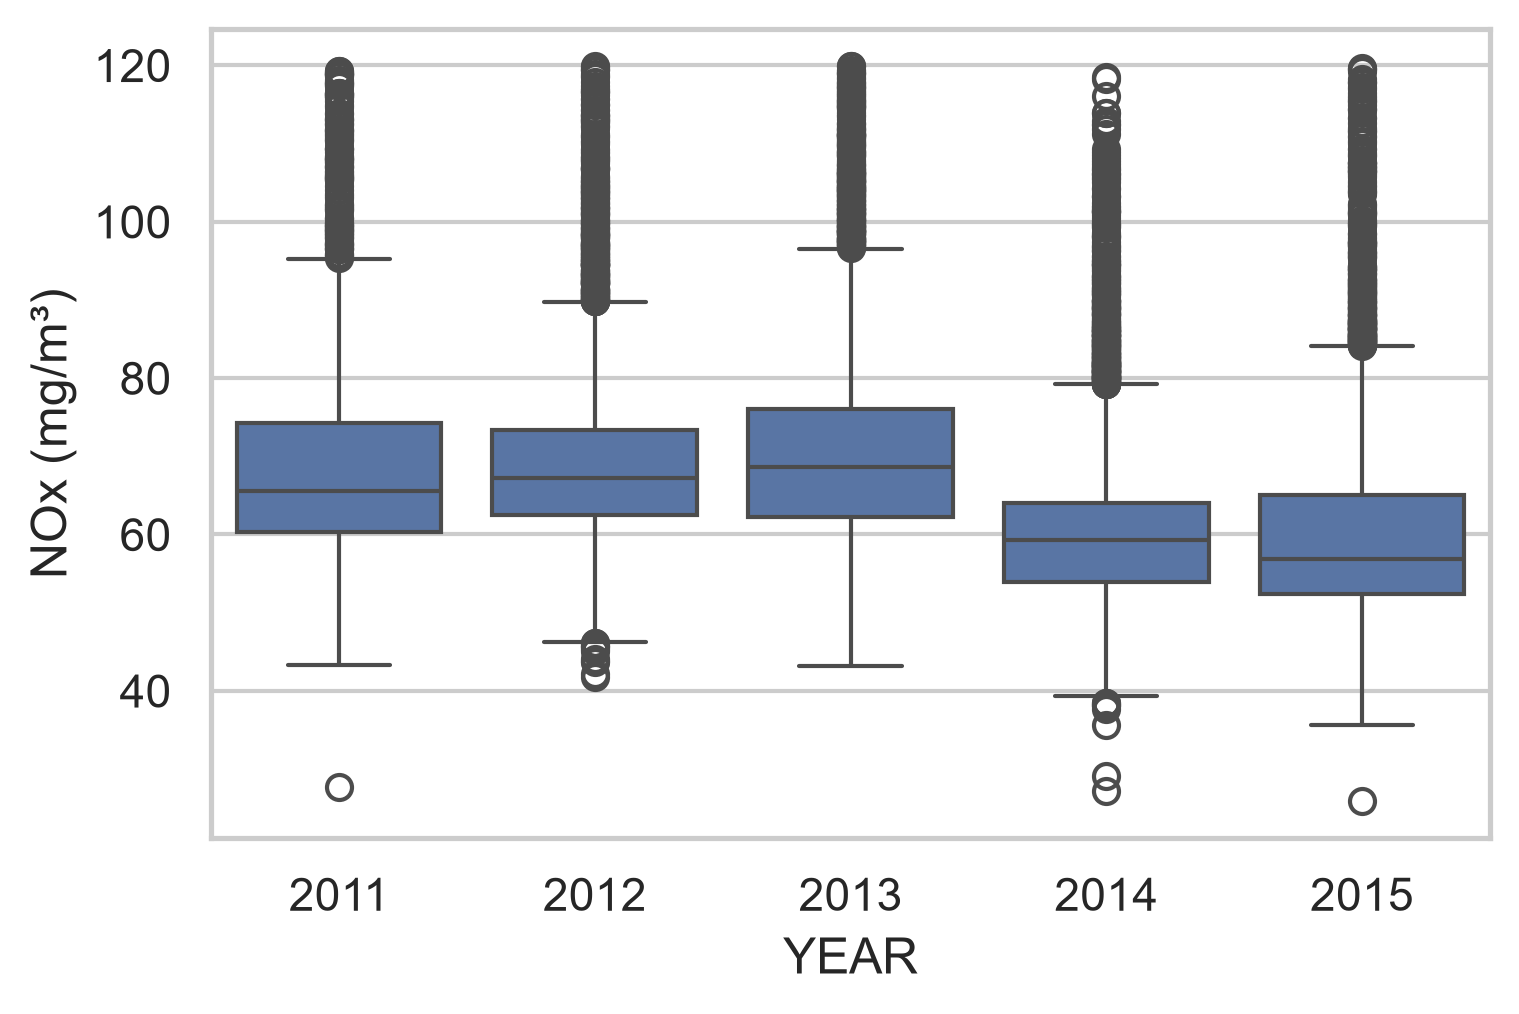

In [4]:
sns.boxplot(data=gt, x="YEAR", y="NOX")
plt.ylabel("NOx (mg/m³)")
plt.show()

The box plots show the distribution of NOx per year. Before testing, look at the size of the differences between the medians compared with the spread within each year – this is what the tests will formalise.

In [5]:
#| code-fold: false
groups = [g["NOX"].values for _, g in gt.groupby("YEAR")]
print("ANOVA:         ", stats.f_oneway(*groups))
print("Kruskal-Wallis:", stats.kruskal(*groups))

a, b = gt.loc[gt.YEAR == 2011, "NOX"], gt.loc[gt.YEAR == 2015, "NOX"]
res = stats.ttest_ind(a, b, equal_var=False)
ci = res.confidence_interval(0.95)
cohens_d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
print(f"Welch t-test 2011 vs 2015: p = {res.pvalue:.2e}")
print(f"difference = {a.mean() - b.mean():.1f} mg/m³, 95 % CI [{ci.low:.1f}, {ci.high:.1f}], Cohen's d = {cohens_d:.2f}")

ANOVA:          F_onewayResult(statistic=np.float64(1495.9585853305857), pvalue=np.float64(0.0))
Kruskal-Wallis: KruskalResult(statistic=np.float64(6795.540640131331), pvalue=np.float64(0.0))
Welch t-test 2011 vs 2015: p = 0.00e+00
difference = 7.7 mg/m³, 95 % CI [7.3, 8.0], Cohen's d = 0.70


**Discussion.** With several thousand hourly values per year, the p-values are astronomically small – any systematic difference between years is detected. The informative numbers are the difference in mg/m³ with its confidence interval and Cohen's d. Whether the change matters depends on the distance to the emission limit and on the cause.

And here an engineering caution is needed: the hourly values are **not independent** – consecutive hours are strongly correlated, so the effective sample size is much smaller than the number of rows, and the p-values are too optimistic. Moreover, differences between years can be caused by different ambient conditions (a hot year), different load profiles or maintenance work. A test can establish *that* the years differ, not *why*. To attribute the change to a cause we would need a model that accounts for these influences (Chapter 5).

## Live coding: product variant and machine failures

The AI4I dataset is a synthetic dataset modelled on a real milling process. Each of the 10,000 records belongs to a product of quality variant L (low, 50 % of products), M (medium, 30 %) or H (high, 20 %). Is the failure rate independent of the variant? Both variables are categorical, so we use the chi-squared test.

In [6]:
#| code-fold: false
from ucimlrepo import fetch_ucirepo

ai4i = fetch_ucirepo(id=601).data.original
table = pd.crosstab(ai4i["Type"], ai4i["Machine failure"])
chi2, p, dof, expected = stats.chi2_contingency(table)
print(table, f"\nchi2 = {chi2:.2f}, dof = {dof}, p = {p:.3f}")
(table[1] / table.sum(axis=1)).rename("failure rate").round(4)

Machine failure     0    1
Type                      
H                 982   21
L                5765  235
M                2914   83 
chi2 = 13.75, dof = 2, p = 0.001


Type
H    0.0209
L    0.0392
M    0.0277
Name: failure rate, dtype: float64

**Discussion.** Compare the failure rates per variant and the p-value. The chi-squared test needs sufficiently large expected counts (rule of thumb: at least 5 in every cell) – check `expected`. Even if the test is significant, ask whether the difference in failure rates is relevant, and whether the variants differ in other respects (e.g. tool wear or load) that could explain it.

## How many measurements do we need?

Planning comes before testing. If a difference of $\delta$ is relevant, how many samples are needed to detect it with a power of, say, 80 %? For the two-sample t-test, the required number per group is approximately

$$n \approx \frac{2\,(z_{1-\alpha/2} + z_{1-\beta})^2}{d^2}, \qquad d = \delta/\sigma,$$

where $\delta$ is the smallest relevant difference, $\sigma$ the standard deviation and $z_q$ the $q$-quantile of the standard normal distribution. This gives about $16/d^2$ for $\alpha = 0.05$ and power 0.8. Halving the detectable effect requires four times as many samples.

In [7]:
#| code-fold: false
from statsmodels.stats.power import TTestIndPower

power_analysis = TTestIndPower()
for d in [0.2, 0.5, 0.8]:
    n = power_analysis.solve_power(effect_size=d, alpha=0.05, power=0.8)
    print(f"d = {d}: n = {np.ceil(n):.0f} per group")

d = 0.2: n = 394 per group
d = 0.5: n = 64 per group
d = 0.8: n = 26 per group


## Back to the decision

The contract requires two things: the reduction must be *demonstrable* (larger than random variation) and *relevant* (at least 5 % of the 2011 mean). A small p-value only covers the first part. We therefore look at the confidence interval of the difference: the bonus is justified only if the whole interval lies above the relevance threshold.

In [8]:
#| code-fold: false
nox_2011 = gt.loc[gt.YEAR == 2011, "NOX"]
nox_2015 = gt.loc[gt.YEAR == 2015, "NOX"]
res_bonus = stats.ttest_ind(nox_2011, nox_2015, equal_var=False)
ci_red = res_bonus.confidence_interval(0.95)              # CI of mean(2011) - mean(2015)
threshold = 0.05 * nox_2011.mean()
print(f"Reduction 2011 -> 2015: {nox_2011.mean() - nox_2015.mean():.1f} mg/m³, "
      f"95 % CI [{ci_red.low:.1f}, {ci_red.high:.1f}], relevance threshold {threshold:.1f} mg/m³")
if ci_red.low > threshold:
    print("Decision: claim confirmed – the reduction is demonstrable and relevant.")
elif ci_red.low > 0:
    print("Decision: reduction demonstrable, but not demonstrably relevant – no bonus under the contract.")
else:
    print("Decision: no demonstrable reduction – claim rejected.")

Reduction 2011 -> 2015: 7.7 mg/m³, 95 % CI [7.3, 8.0], relevance threshold 3.4 mg/m³
Decision: claim confirmed – the reduction is demonstrable and relevant.


Two further points belong in the review. The hourly values are autocorrelated, so the true uncertainty is larger than the interval suggests – a borderline case should be decided against the claim. And even a confirmed reduction does not prove that the consultant *caused* it: different weather, load profiles or maintenance could have the same effect. A fair contract would have specified how such influences are accounted for – a lesson for the next one.

::: {.callout-important}
## Key takeaways
- A test checks whether data are compatible with "no effect"; the p-value is a probability *under* $H_0$, not *of* $H_0$.
- Report effect sizes and confidence intervals, not just p-values; judge relevance in physical units.
- Large samples make tiny effects significant; small samples miss relevant effects – plan the sample size.
- Many tests produce false alarms; correct (Bonferroni, Holm) and plan comparisons in advance.
- Tests assume independent observations – time series data violate this.
:::

## Exercises

<div class="exercises">

1. Check the normality assumption for NOx per year with QQ plots. Does a violation matter for the ANOVA with these sample sizes?
2. Draw a random sample of 30 hourly values per year and repeat the ANOVA and the 2011 vs. 2015 t-test. What changes and why? Repeat the sampling a few times.
3. Run pairwise Welch t-tests between all years. How many comparisons are there? Apply a Bonferroni and a Holm correction.
4. Formulate an engineering conclusion from the NOx analysis in two or three sentences – for a plant manager, not for a statistician.
5. A new coating is supposed to reduce the wear of a tool by 10 µm. From previous tests the standard deviation of the wear is 25 µm. How many tools must be tested per variant to detect the improvement with 80 % power ($\alpha = 0.05$)?

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

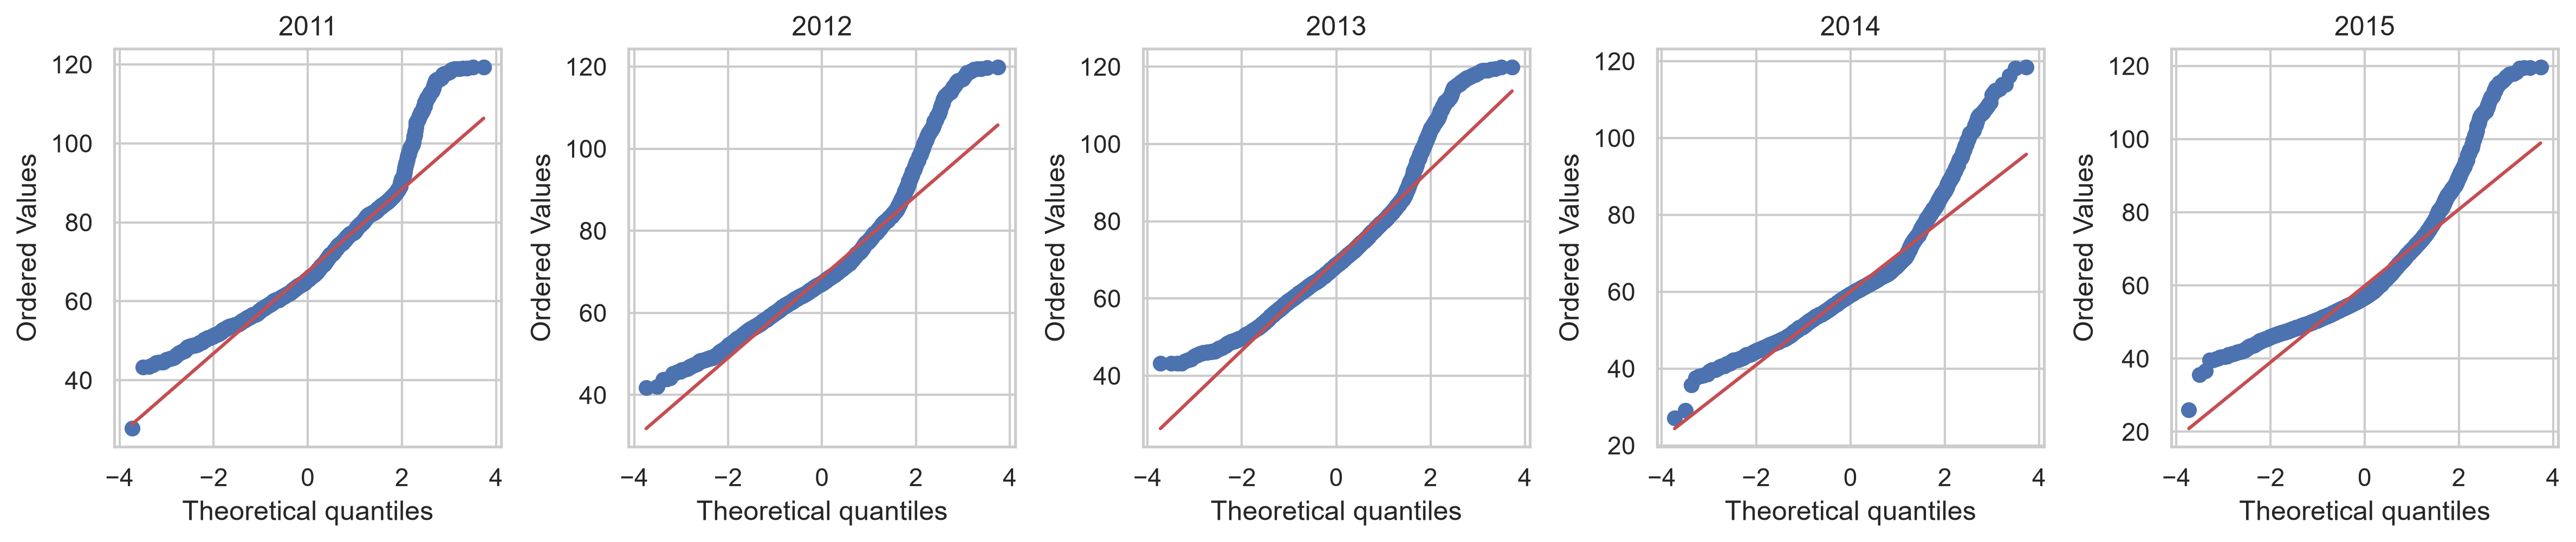

In [9]:
#| code-fold: false
years = sorted(gt["YEAR"].unique())
fig, axes = plt.subplots(1, len(years), figsize=(16, 3.5))
for ax, yr in zip(axes, years):
    stats.probplot(gt.loc[gt.YEAR == yr, "NOX"], dist="norm", plot=ax)
    ax.set_title(str(yr))
plt.tight_layout(); plt.show()

Deviations from the straight line at the ends indicate heavier or lighter tails than the normal distribution, curvature indicates skewness. With thousands of observations per group, the central limit theorem makes the group *means* approximately normal, so the ANOVA is robust against moderate non-normality. More critical are the unequal variances between years and above all the dependence of consecutive hourly values. The Kruskal–Wallis test, which does not assume normality, serves as a cross-check.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2

In [10]:
#| code-fold: false
for seed in range(3):
    small = gt.groupby("YEAR", group_keys=False).sample(30, random_state=seed)
    groups_s = [g["NOX"].values for _, g in small.groupby("YEAR")]
    a_s = small.loc[small.YEAR == 2011, "NOX"]; b_s = small.loc[small.YEAR == 2015, "NOX"]
    print(f"seed {seed}: ANOVA p = {stats.f_oneway(*groups_s).pvalue:.3g}, "
          f"t-test p = {stats.ttest_ind(a_s, b_s, equal_var=False).pvalue:.3g}, "
          f"difference = {a_s.mean() - b_s.mean():.1f} mg/m³")

seed 0: ANOVA p = 0.000462, t-test p = 0.203, difference = 4.5 mg/m³
seed 1: ANOVA p = 5.7e-07, t-test p = 0.000116, difference = 8.8 mg/m³
seed 2: ANOVA p = 7.32e-06, t-test p = 0.0237, difference = 7.0 mg/m³


The estimated differences stay of similar size, but the p-values are much larger and vary from sample to sample: with 30 values per year, the standard error is roughly $\sqrt{7000/30} \approx 15$ times larger. Small differences that were "highly significant" with all data may no longer be detectable. The effect did not change – only the power of the test.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

In [11]:
#| code-fold: false
import itertools
from statsmodels.stats.multitest import multipletests

pairs, pvals = [], []
for y1, y2 in itertools.combinations(years, 2):
    pairs.append(f"{y1}-{y2}")
    pvals.append(stats.ttest_ind(gt.loc[gt.YEAR == y1, "NOX"], gt.loc[gt.YEAR == y2, "NOX"],
                                 equal_var=False).pvalue)
result = pd.DataFrame({"p": pvals,
                       "Bonferroni": multipletests(pvals, method="bonferroni")[1],
                       "Holm": multipletests(pvals, method="holm")[1]}, index=pairs)
result.style.format("{:.2e}")

,p,Bonferroni,Holm
2011-2012,1.18e-12,1.18e-11,3.55e-12
2011-2013,1.01e-37,1.01e-36,4.06e-37
2011-2014,0.00e+00,0.00e+00,0.00e+00
2011-2015,0.00e+00,0.00e+00,0.00e+00
2012-2013,3.97e-11,3.97e-10,7.94e-11
2012-2014,0.00e+00,0.00e+00,0.00e+00
2012-2015,0.00e+00,0.00e+00,0.00e+00
2013-2014,0.00e+00,0.00e+00,0.00e+00
2013-2015,0.00e+00,0.00e+00,0.00e+00
2014-2015,3.14e-01,1.00e+00,3.14e-01


With 5 years there are $\binom{5}{2} = 10$ comparisons. Bonferroni multiplies each p-value by 10 (capped at 1); Holm multiplies the smallest by 10, the next by 9 and so on, and is therefore less conservative. With these large samples most comparisons remain significant even after correction – the correction matters most when p-values are close to $\alpha$.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4
A good answer states the size of the change in physical units, relates it to a meaningful reference and names the limits of the analysis, for example: "The mean NOx emission in 2015 was X mg/m³ lower (higher) than in 2011, a change of about Y % of the typical level. This difference is clearly larger than random variation. The data alone do not show whether the change was caused by maintenance, different operation or different weather; to find out, we should model the emissions as a function of load and ambient conditions." (Insert X and Y from your results.) Avoid statistical jargon such as "p < 0.001" without explanation.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5

In [12]:
#| code-fold: false
d = 10 / 25
n = TTestIndPower().solve_power(effect_size=d, alpha=0.05, power=0.8)
print(f"d = {d}, n = {np.ceil(n):.0f} tools per variant (rule of thumb 16/d² = {16 / d**2:.0f})")

d = 0.4, n = 100 tools per variant (rule of thumb 16/d² = 100)


The effect size is $d = 10/25 = 0.4$, which requires about 100 tools per variant. If that is too expensive, options are: reduce the noise (more homogeneous test conditions, paired design with both coatings on the same machine), accept a lower power, or test for a larger minimum effect.
:::